# 01 · Data Exploration

**Goal:** understand the data before building a model.

- **Input:** `data/raw/train.csv` (221 fires with answers)
- **Output:** 4 charts in `reports/figures/`, and `data/processed/train_clean.csv`

**Question:** *when* will a fire get within 5 km of an evacuation zone, and what is the chance (%) it happens within 12, 24, 48 or 72 hours?

This is a **survival analysis** problem: for fires that never reached a zone, we only know they had not hit by the time we stopped watching them (they are *censored*).

In [1]:
# Libraries used in this notebook
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Hide noisy warnings and find the project folders
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Project helpers: loading, cleaning, labels, extra features and the Kaplan-Meier curve
from src.data import load_raw, clean, make_labels, feature_columns, HORIZONS, TIME_COL, EVENT_COL
from src.features import add_features
from src.survival import hit_curve

## 1. Load and check the data

In [2]:
# Load the raw files and remove duplicates / infinite values
train, test = load_raw(DATA_DIR / "raw")
train = clean(train)
FEATURES = feature_columns(train)

# Quick data-quality check: size, missing values, duplicate fires
print("Train:", train.shape, "| Test:", test.shape)
print("Missing values:", train.isna().sum().sum(), "| Duplicate fires:", train["event_id"].duplicated().sum())
train.head()

Train: (221, 37) | Test: (95, 35)
Missing values: 0 | Duplicate fires: 0


,event_id,num_perimeters_0_5h,dt_first_last_0_5h,low_temporal_resolution_0_5h,area_first_ha,area_growth_abs_0_5h,area_growth_rel_0_5h,area_growth_rate_ha_per_h,log1p_area_first,log1p_growth,...,dist_fit_r2_0_5h,alignment_cos,alignment_abs,cross_track_component,along_track_speed,event_start_hour,event_start_dayofweek,event_start_month,time_to_hit_hours,event
0,10892457,3,4.265188,0,79.696304,2.875935,0.036086,0.674281,4.390693,1.354787,...,0.886373,-0.054649,0.054649,-1.937219,-0.106026,19,4,5,18.892512,0
1,11757157,2,1.169918,0,8.946749,0.000000,0.000000,0.000000,2.297246,0.000000,...,0.000000,-0.568898,0.568898,-0.000000,-0.000000,4,4,6,22.048108,1
2,11945086,4,4.777526,0,106.482638,0.000000,0.000000,0.000000,4.677329,0.000000,...,0.000000,0.882385,0.882385,0.000000,0.000000,22,4,8,0.888895,1
3,12044083,1,0.000000,1,67.631125,0.000000,0.000000,0.000000,4.228746,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,20,5,8,60.953021,0
4,12052347,2,4.975273,0,35.632874,0.000000,0.000000,0.000000,3.600946,0.000000,...,0.000000,0.934634,0.934634,-0.000000,0.000000,21,5,7,44.990274,0


Clean data: 34 numeric features, no missing values, no duplicates.

## 2. The target
- `event`: 1 = the fire reached the zone, 0 = censored (we stopped watching it before it hit)
- `time_to_hit_hours`: when it reached the zone, or when we stopped watching it

**Competition rule:** if we stopped watching a fire *before* a time limit, we don't know what happened, so that fire is **skipped** for that limit.

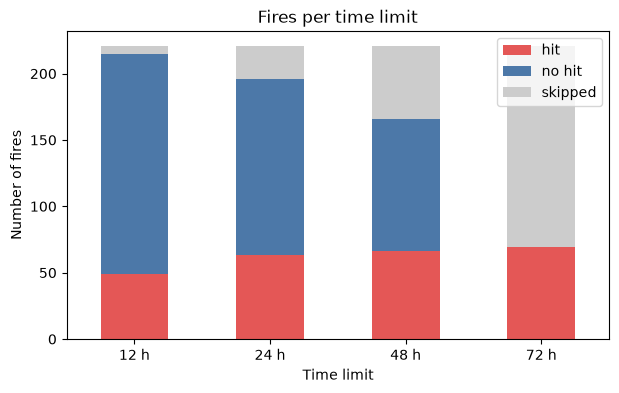

,hit,no hit,skipped
12 h,49,166,6
24 h,63,133,25
48 h,66,100,55
72 h,69,0,152


In [3]:
# Build hit / no hit / skipped labels for each time limit and count them
labels = make_labels(train[TIME_COL], train[EVENT_COL])
counts = pd.DataFrame({"hit": (labels == 1).sum(), "no hit": (labels == 0).sum(), "skipped": labels.isna().sum()})
counts.index = [f"{h} h" for h in HORIZONS]

# Stacked bar chart of the counts, saved as a PNG
counts.plot.bar(stacked=True, color=["#E45756", "#4C78A8", "#CCCCCC"], figsize=(7, 4), rot=0)
plt.title("Fires per time limit")
plt.xlabel("Time limit"); plt.ylabel("Number of fires")
plt.savefig(FIG_DIR / "01_target.png", bbox_inches="tight"); plt.show()
counts

Only **31%** of fires reach the zone. Many censored fires were last seen before 72 h, so they are skipped at the later limits.

## 3. Time until a fire hits (Kaplan–Meier curve)
The **Kaplan–Meier** curve is the standard survival-analysis chart. It shows the share of fires that have reached a zone by each hour, and it uses censored fires correctly: a fire last seen at 40 h counts as "not hit yet" up to 40 h and is then removed from the count. Each curve stops once fewer than 10 fires are still being watched.

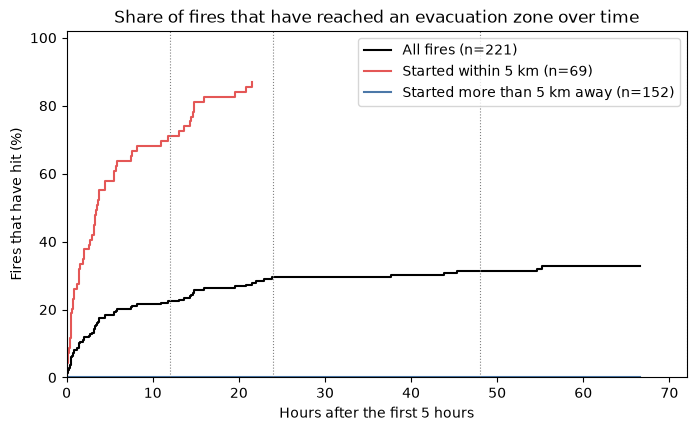

In [4]:
# Kaplan-Meier curves: all fires, then fires that started near vs. far from a zone
near = train["dist_min_ci_0_5h"] <= 5000
plt.figure(figsize=(8, 4.5))
for mask, label, color in [(train.index == train.index, "All fires", "black"),
                           (near, "Started within 5 km", "#E45756"),
                           (~near, "Started more than 5 km away", "#4C78A8")]:
    t, p = hit_curve(train.loc[mask, TIME_COL], train.loc[mask, EVENT_COL])
    plt.step(np.r_[0, t], np.r_[0, p] * 100, where="post", label=f"{label} (n={mask.sum()})", color=color)
for h in HORIZONS: plt.axvline(h, color="grey", linestyle=":", linewidth=0.8)
plt.title("Share of fires that have reached an evacuation zone over time")
plt.xlabel("Hours after the first 5 hours"); plt.ylabel("Fires that have hit (%)"); plt.xlim(0, 72); plt.ylim(0, 102)
plt.legend(); plt.savefig(FIG_DIR / "01_kaplan_meier.png", bbox_inches="tight"); plt.show()

Most hits happen in the **first 12 hours**, and then the curve flattens. Fires that start within 5 km almost all hit; fires farther away never do.

## 4. Distance decides almost everything

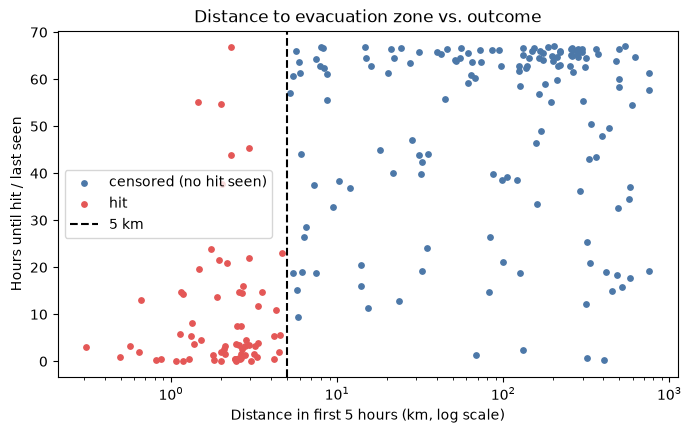

Farthest fire that hit: 4.7 km
Closest fire that did not hit: 5.2 km


In [5]:
# Scatter: distance to the evacuation zone vs. hours, coloured by outcome
hit = train[EVENT_COL] == 1
plt.figure(figsize=(8, 4.5))
plt.scatter(train.loc[~hit, "dist_min_ci_0_5h"] / 1000, train.loc[~hit, TIME_COL], color="#4C78A8", s=15, label="censored (no hit seen)")
plt.scatter(train.loc[hit, "dist_min_ci_0_5h"] / 1000, train.loc[hit, TIME_COL], color="#E45756", s=15, label="hit")
plt.axvline(5, color="black", linestyle="--", label="5 km")
plt.xscale("log")
plt.title("Distance to evacuation zone vs. outcome")
plt.xlabel("Distance in first 5 hours (km, log scale)"); plt.ylabel("Hours until hit / last seen")
plt.legend(); plt.savefig(FIG_DIR / "01_distance.png", bbox_inches="tight"); plt.show()

# The two numbers behind the key finding
print("Farthest fire that hit: %.1f km" % (train.loc[hit, "dist_min_ci_0_5h"].max() / 1000))
print("Closest fire that did not hit: %.1f km" % (train.loc[~hit, "dist_min_ci_0_5h"].min() / 1000))

⚠️ **Key finding:** every fire that hit started **within 4.7 km** of the zone, and every censored fire was **more than 5.2 km** away.
So *whether* a fire hits is easy to predict. The hard part is *when*, which is why we use survival models.

## 5. Which features are most linked to a hit?

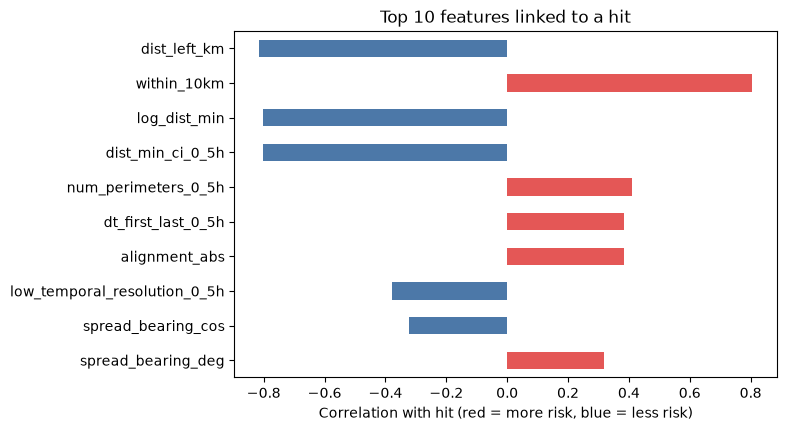

In [6]:
# Add the extra features, then rank all features by how linked they are to a hit
X = add_features(train[FEATURES])
corr = X.corrwith(train[EVENT_COL], method="spearman").dropna()
top = corr.reindex(corr.abs().sort_values().index).tail(10)

# Bar chart of the top 10 features, saved as a PNG
top.plot.barh(color=["#E45756" if v > 0 else "#4C78A8" for v in top], figsize=(7, 4.5))
plt.title("Top 10 features linked to a hit")
plt.xlabel("Correlation with hit (red = more risk, blue = less risk)"); plt.ylabel("")
plt.savefig(FIG_DIR / "01_top_features.png", bbox_inches="tight"); plt.show()

Distance features are at the top. Fires that were mapped more often and moved toward the zone are also riskier.

In [7]:
# Save the cleaned data for notebook 02
(DATA_DIR / "processed").mkdir(exist_ok=True)
train.to_csv(DATA_DIR / "processed" / "train_clean.csv", index=False)

## Key Findings
1. **Survival problem:** 69% of fires are censored (no hit seen), so we need models that handle censoring.
2. **Hits come early:** the Kaplan–Meier curve rises fast in the first 12 hours, then flattens.
3. **Distance is the main signal:** fires within about 5 km hit. *When* they hit is the real challenge.
4. **Small data:** only 221 fires, so we use cross-validation to compare models.